In [1]:
import os
import cv2
import numpy as np
from tqdm import tqdm
import torch.optim as optim
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import json
import torchvision
from torchvision import transforms
from torchvision.utils import save_image, make_grid
from torch.utils.data import Subset, random_split
from glob import glob
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from PIL import Image
import pandas as pd
import shutil
from pycocotools import mask as coco_mask
import os
from glob import glob
import matplotlib.pyplot as plt

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

In [ ]:
!pip3 install torch torchvision transformers pillow

In [ ]:
# import os

# from google.colab import drive
# drive.mount('/content/drive')

In [3]:
!git clone https://github.com/jasonfghx/retina_image.git

Cloning into 'retina_image'...
remote: Enumerating objects: 3734, done.
remote: Counting objects: 100% (340/340), done.
remote: Compressing objects: 100% (328/328), done.
remote: Total 3734 (delta 35), reused 11 (delta 11), pack-reused 3394 (from 3)
Receiving objects: 100% (3734/3734), 478.50 MiB | 25.10 MiB/s, done.
Resolving deltas: 100% (240/240), done.
Updating files: 100% (3272/3272), done.


In [4]:
from transformers import SegformerForSemanticSegmentation

NUM_CLASSES = 2  # 例：背景 + 目標

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b1-finetuned-ade-512-512",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
)

config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 54.9MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b1-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [5]:
from transformers import SegformerForSemanticSegmentation

NUM_CLASSES = 2  # 例：背景 + 目標

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b5",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
)
# pamixsun/segformer_for_optic_disc_cup_segmentation
# nvidia/mit-b4
#  = 'nvidia/mit-b0'
#  'nvidia/mit-b1'
#  'nvidia/mit-b2'
#  'nvidia/mit-b3'

#  'nvidia/mit-b5'

model.safetensors: reconstructing file:   0%|          |  0.00B /  328MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1156 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b5
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_fuse.weight                          

In [6]:
from torch.utils.data import Dataset
from PIL import Image
import os
import numpy as np
from transformers import SegformerImageProcessor
processor = SegformerImageProcessor.from_pretrained(
    "nvidia/mit-b5"
)
class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir):
        self.imgs = sorted(os.listdir(img_dir))
        self.img_dir = img_dir
        self.mask_dir = mask_dir

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img = Image.open(
            os.path.join(self.img_dir, self.imgs[idx])
        ).convert("RGB")

        mask = Image.open(
            os.path.join(self.mask_dir, self.imgs[idx])
        ).convert("L")
        mask = np.array(mask)
        mask = (mask > 0).astype(np.uint8)
        inputs = processor(
            images=img,
            segmentation_maps=mask,
            return_tensors="pt"
        )

        return {
            "pixel_values": inputs["pixel_values"][0],
            "labels": inputs["labels"].squeeze(0)
        }


preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

In [7]:
import cv2
import os
import numpy as np
os.makedirs('/content/retina_image/train')
os.makedirs('/content/retina_image/train/images')
os.makedirs('/content/retina_image/train/labels')

In [13]:
add=glob("/content/retina_image/s1/images/*")
for i in add[:]:
    image = cv2.imread(i)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=10.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    enhanced_lab = cv2.merge([cl,a,b])
    image = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)
# 转换为灰度图像
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# 应用高斯模糊以减少噪声
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    blurred=cv2.medianBlur(blurred,3)
# 使用自适应阈值分割图像
    thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 15, 10)

# 使用形态学操作以细化结果
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
    morph = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=1)
# 使用自适应阈值分割图像
    rho = 1  # distance resolution in pixels of the Hough grid
    theta = np.pi / 180  # angular resolution in radians of the Hough grid
    threshold = 20  # minimum number of votes (intersections in Hough grid cell)
    min_line_length = 110  # minimum number of pixels making up a line
    max_line_gap = 20  # maximum gap in pixels between connectable line segments

    lines = cv2.HoughLinesP(morph, rho, theta, threshold, np.array([]),
                    min_line_length, max_line_gap)
    point_p_l=[]
    for line in lines:
      for x1,y1,x2,y2 in line:
          if y1<1750 and y1>500 and x1<1750 and x1>500 and x2<1700:
            if image[x1,y1][0]<125 and image[x2,y2][0]<125 and image[x2,y2][1]<140 and image[x1,y1][1]<140 and image[x1,y1][2]<130:
                point_p_l.append((x1,y1))
                point_p_l.append((x2,y2))
    #             cv2.line(image,(x1,y1),(x2,y2),(255,0,0),5)
    # plt.imshow(image)
    # plt.show()
    if len(point_p_l)!=0:
        hull = cv2.convexHull(np.array(point_p_l))
        cv2.fillPoly(image, [np.array((hull))], (0, 0,0))
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# # 定義紅色範圍（根據需求調整）
    lower_red1 = np.array([0, 70, 50])  # 第一部分紅色範圍（低色調）
    upper_red1 = np.array([10, 255, 255])

    lower_red2 = np.array([170, 70, 50])  # 第二部分紅色範圍（高色調）
    upper_red2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
    red_mask = cv2.bitwise_or(mask1, mask2)
    image[red_mask > 0] = [0, 0, 0]
    #name=i.split("/")[-1]
    name = os.path.basename(i)
    cv2.imwrite('/content/retina_image/train/images/'+name,image)
add=glob("/content/retina_image/s1/masks/*")
for i in add[:]:
    image = cv2.imread(i)
    name = os.path.basename(i)
    cv2.imwrite('/content/retina_image/train/labels/'+name.replace("png",'jpg'),image)


In [11]:
os.path.basename(i)

'Stage_1_ROP_45.jpg'

['C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_10.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_100.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1000.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1001.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1002.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1003.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1004.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1005.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1006.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s1/images01_png\\Stage_1_ROP_1007.png', 'C:/Users/chenk/Desktop/segformer/retina_image/s

In [14]:
from torch.utils.data import DataLoader, random_split

# 建立完整 Dataset
dataset = SegDataset(
    "/content/retina_image/train/images",
    "/content/retina_image/train/labels"
)

# 設定 80% Train、20% Validation
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

# 固定亂數種子，確保每次分割結果相同
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=generator
)

# Train Loader
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True
)

# Validation Loader
val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False
)

print("Total images:", len(dataset))
print("Train images:", len(train_dataset))
print("Val images:", len(val_dataset))


Total images: 93
Train images: 74
Val images: 19


In [15]:
loss_history = []
loss_history_v=[]
import torch
from torch.optim import AdamW
from transformers import SegformerImageProcessor

processor = SegformerImageProcessor(
    do_resize=True,
    size=512,
    do_normalize=True
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

optimizer = AdamW(model.parameters(), lr=6e-5)

model.train()

for epoch in range(10):
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()

        outputs = model(
            pixel_values=batch["pixel_values"].to(device),
            labels=batch["labels"].to(device)
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch}: loss = {total_loss:.4f}")

    loss_history.append(total_loss)
    model.eval()

    val_loss = 0.0
    val_batches = 0

    with torch.no_grad():

        for batch in val_loader:

            outputs = model(
            pixel_values=batch["pixel_values"].to(device),
            labels=batch["labels"].to(device)
        )

            loss = outputs.loss

            val_loss += loss.item()
            val_batches += 1

    avg_val_loss = val_loss / val_batches
    loss_history_v.append(avg_val_loss)



Epoch 0: loss = 9.3465
Epoch 1: loss = 1.8265
Epoch 2: loss = 0.7416
Epoch 3: loss = 0.5344
Epoch 4: loss = 0.4449
Epoch 5: loss = 0.3854
Epoch 6: loss = 0.3637
Epoch 7: loss = 0.3333
Epoch 8: loss = 0.3245
Epoch 9: loss = 0.3132


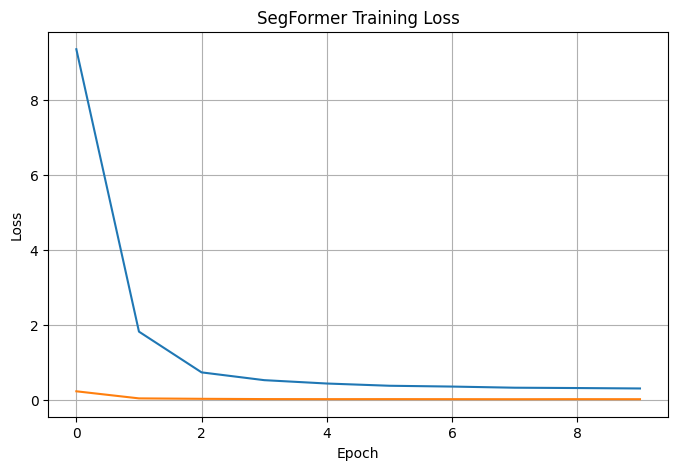

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(loss_history)
plt.plot(loss_history_v)
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("SegFormer Training Loss")

plt.grid(True)

plt.show()

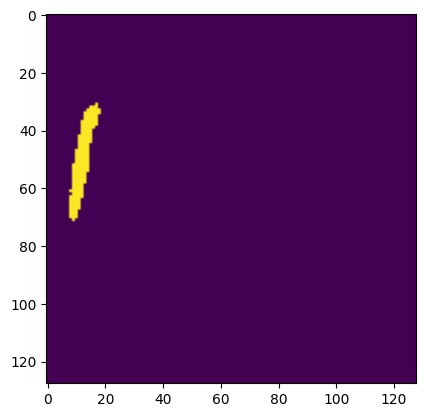

In [18]:
import torch
import numpy as np
from PIL import Image

@torch.no_grad()
def predict(image_path):
    img = Image.open(image_path).convert("RGB")
    inputs = processor(
        images=img,
        return_tensors="pt"
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}
    outputs = model(**inputs)
    logits = outputs.logits
    pred = torch.argmax(logits, dim=1)
    pred = pred.squeeze(0).cpu().numpy()

    return pred
mask = predict("/content/retina_image/train/images/Stage_1_ROP_2.jpg")
pred_img = (mask * 255).astype(np.uint8)
plt.imshow(pred_img)

In [ ]:
# import timm
# timm.create_model(
#             'swin_tiny_patch4_window7_224',
#             pretrained=True,
#             features_only=True)
